Exercise 10.3 (Visualizing the AI4I data with seaborn)
In this exercise you will explore the AI4I dataset (columns UDI , Torque , Rotational speed and Air temperature )
using seaborn .

Basic plots
1. Load the AI4I dataset (keeping only Torque , Rotational speed and Air temperature ).
2. Create a line plot of Torque over UDI .
3. Create a histogram of each column to observe the distribution of values.
4. Create box plots of each column to identify outliers and understand the spread of the data.
5. Create violin plots of each column and discuss how they differ from box plots.

Relationships between variables
1. Create a scatter plot of Torque vs Rotational speed using sns.scatterplot . Add Air temperature as the hue parameter to see how the third variable influences the relationship.
2. Create a pair plot ( sns.pairplot ) of all three numeric columns to observe pairwise relationships and distributions on the diagonal.
3. Create a correlation heatmap using sns.heatmap on the correlation matrix of the three columns. Discuss which ariables are most strongly correlated.

Advanced plots
1. Create a joint plot of Torque vs Air temperature with a regression line overlay.
2. Create a strip plot or swarm plot of Torque colored by a binned version of Rotational speed (e.g.,
low/medium/high using pd.cut ).
3. Create a count plot showing the distribution of data points across bins of Torque (e.g., binned into 10 intervals).

Observations
1. Based on all the plots above, answer the following:
    Are there any obvious outliers in the data?
    Which two variables seem most related?
    Are there any non-linear patterns visible?
    How are the distributions shaped?
    After this exercise you should be able to:
1. Create a wide range of static statistical plots with seaborn .
2. Use parameters to add additional dimensions to your plots.
3. Compare and discuss different plot types for different analytical questions.
4. Draw meaningful observations from statistical visualizations.


Basic plots:

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns               # Zur statistischen visualisierung von Daten


# Legt die URL des AI4I-Datensatzes fest.
url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

# Liest den Datensatz ein und speichert ihn als Pandas DataFrame.
df = pd.read_csv(url)

# Behält die drei Messgrößen und die UDI für das Liniendiagramm.
df = df[["UDI", "Torque [Nm]", "Rotational speed [rpm]", "Air temperature [K]"]]

# Zeigt die ersten fünf Datensätze zur Kontrolle an.
df.head()

,UDI,Torque [Nm],Rotational speed [rpm],Air temperature [K]
0,1,42.8,1551,298.1
1,2,46.3,1408,298.2
2,3,49.4,1498,298.1
3,4,39.5,1433,298.2
4,5,40.0,1408,298.2


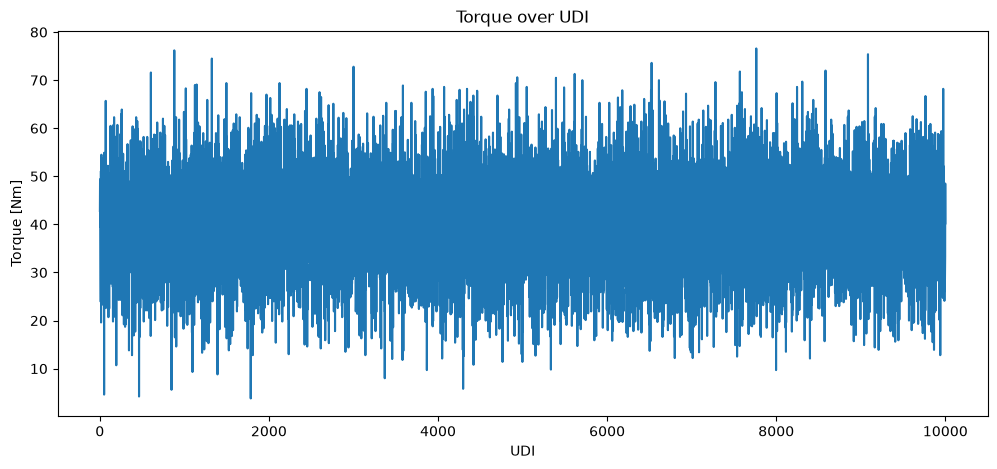

In [2]:
# Erstellt eine neue Abbildung mit festgelegter Größe.
plt.figure(figsize=(12, 5))

# Zeichnet das Drehmoment über der UDI als Liniendiagramm.
# data gibt den verwendeten DataFrame an.
# x und y legen die Spalten für die beiden Achsen fest.
sns.lineplot(data=df, x="UDI", y="Torque [Nm]")

# Fügt einen Titel und Achsenbeschriftungen hinzu.
plt.title("Torque over UDI")
plt.xlabel("UDI")
plt.ylabel("Torque [Nm]")

# Zeigt das fertige Diagramm an.
plt.show()

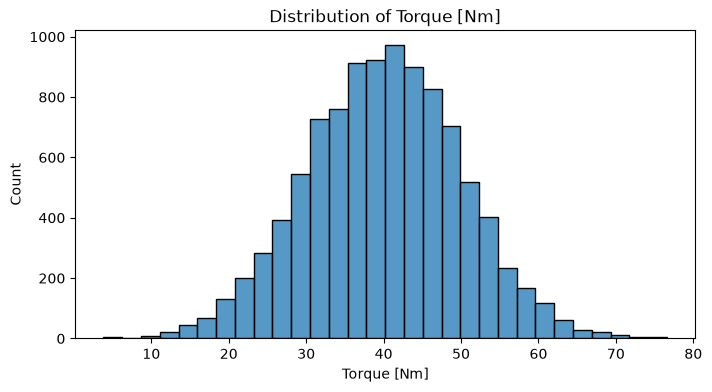

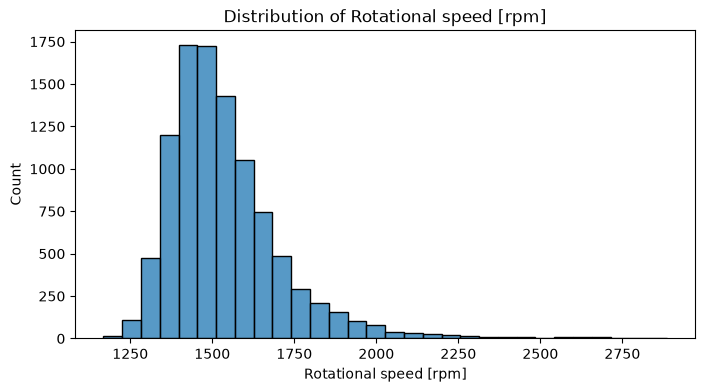

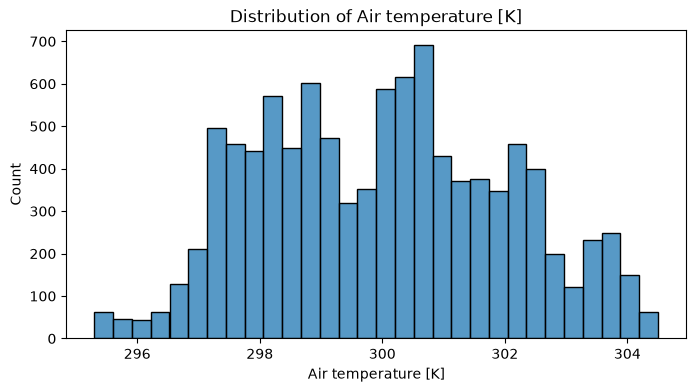

In [3]:
# Legt die drei Messgrößen fest, deren Verteilungen untersucht werden sollen.
columns = ["Torque [Nm]", "Rotational speed [rpm]", "Air temperature [K]"]

# Erstellt für jede Messgröße ein eigenes Histogramm.
for column in columns:

    # Erstellt eine neue Abbildung mit einer Breite von 8 und Höhe von 4 Zoll.
    plt.figure(figsize=(8, 4))

    # Erstellt ein Histogramm für die ausgewählte Messgröße.
    # data gibt den DataFrame an, x die darzustellende Spalte.
    # bins=30 teilt den Wertebereich in 30 Klassen ein.
    sns.histplot(data=df, x=column, bins=30)

    # Verwendet den Namen der Messgröße als Diagrammtitel.
    plt.title(f"Distribution of {column}")

    # Beschriftet die x-Achse mit der jeweiligen Messgröße.
    plt.xlabel(column)

    # Beschriftet die y-Achse mit der Anzahl der Messwerte pro Klasse.
    plt.ylabel("Count")

    # Zeigt das aktuelle Histogramm an.
    plt.show()

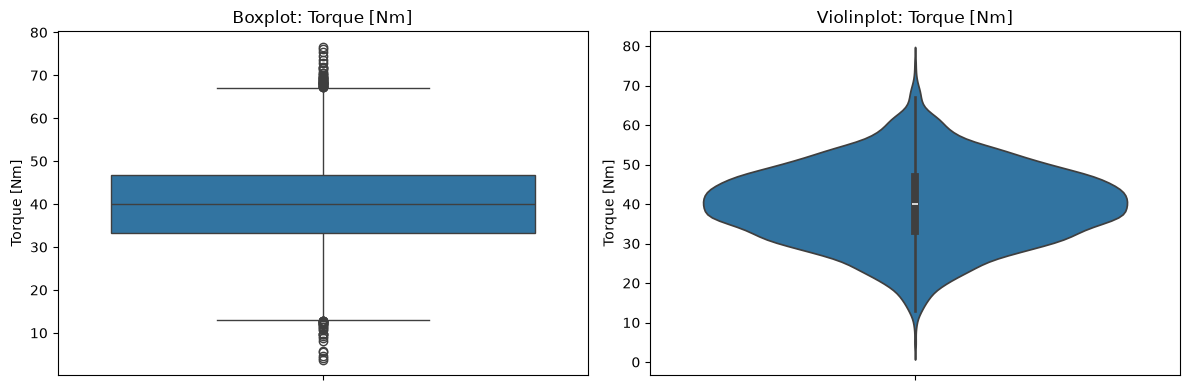

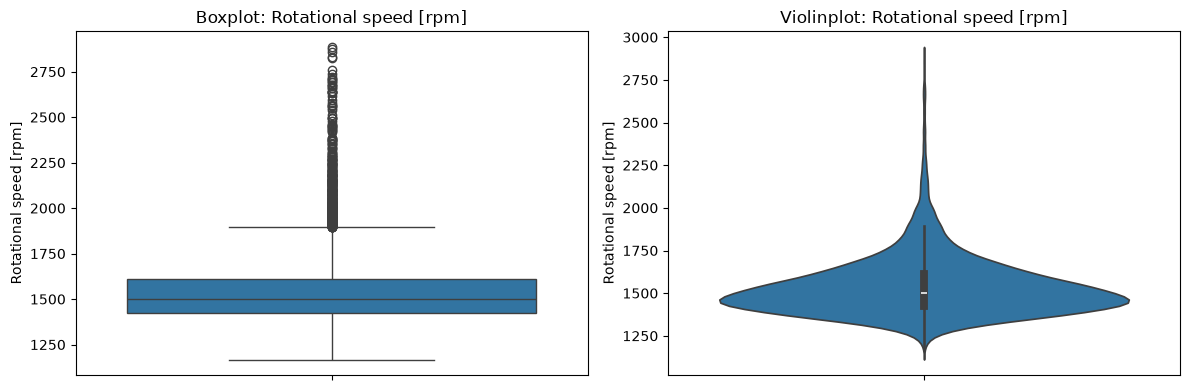

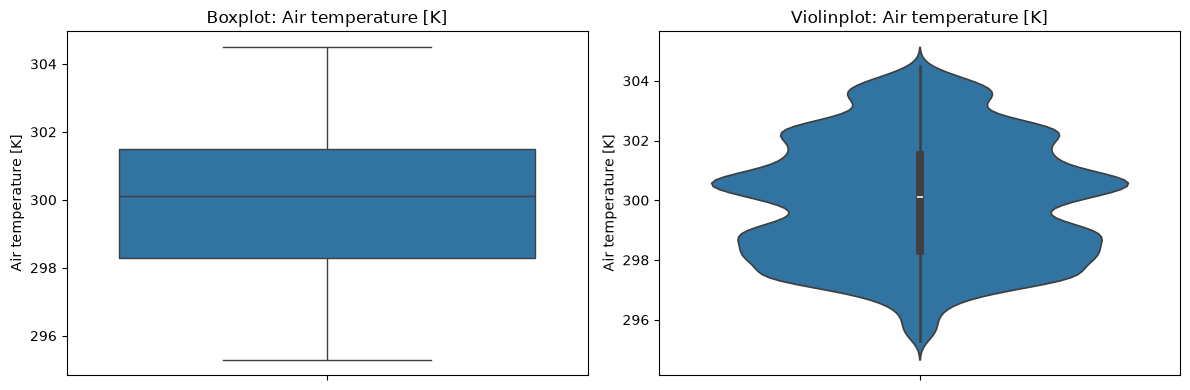

In [ ]:
# Legt die drei Messgrößen für die Auswertung fest.
columns = ["Torque [Nm]", "Rotational speed [rpm]", "Air temperature [K]"]

# Durchläuft die drei Messgrößen nacheinander.
for column in columns:

    # Erstellt eine Abbildung mit zwei Diagrammen nebeneinander.
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Erstellt einen Boxplot für die aktuelle Messgröße.
    # Der Boxplot zeigt Median, Quartile und mögliche Ausreißer.
    # IQR = Q3 - Q1, wobei Q1 das 25. Perzentil und Q3 das 75. Perzentil ist.
    # Standard whis=1,5 -> 1,5 * IQR (Interquartilsabstand) für die Whisker-Länge.
    sns.boxplot(data=df, y=column, ax=axes[0])
    axes[0].set_title(f"Boxplot: {column}")

    # Erstellt einen Violinplot für dieselbe Messgröße.
    # Die Breite der Violine zeigt die geschätzte Dichte der Messwerte.
    sns.violinplot(data=df, y=column, ax=axes[1])
    axes[1].set_title(f"Violinplot: {column}")

    # Passt die Abstände zwischen den Diagrammen automatisch an.
    plt.tight_layout()

    # Zeigt die beiden Diagramme an.
    plt.show()

Unterschied Boxplot und Violinplot:

Boxplot fasst die statistischen Kennwerte zusammen während der Violinplot zusätzlich zeigt, wie die Messwerte verteilt sind.

Relationships between variables:

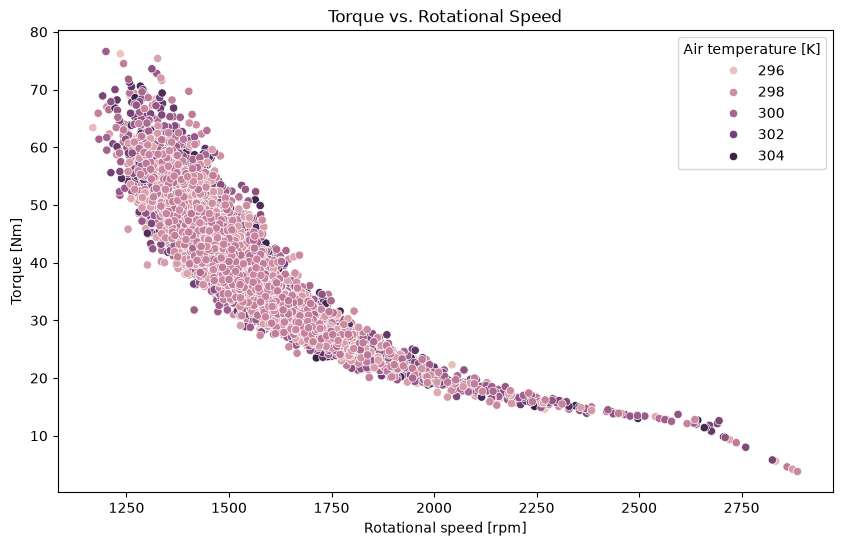

In [ ]:
# Scatter plot 
plt.figure(figsize=(10, 6))

# Erstellt ein Streudiagramm der Drehzahl und des Drehmoments.
# Jeder Punkt stellt einen einzelnen Datensatz dar.
# Die Farbe der Punkte zeigt die jeweilige Lufttemperatur.
sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Air temperature [K]"
)

# Fügt einen Titel und die Achsenbeschriftungen hinzu.
plt.title("Torque vs. Rotational Speed")
plt.xlabel("Rotational speed [rpm]")
plt.ylabel("Torque [Nm]")

# Zeigt das Diagramm an.
plt.show()

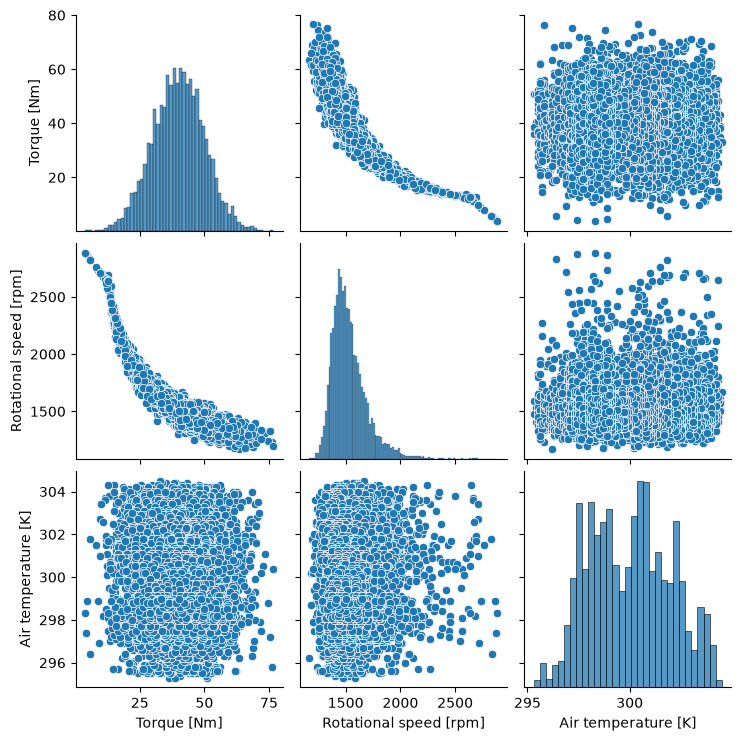

In [6]:
# pair plot
# Wählt die drei Messgrößen für den Vergleich aus.
columns = ["Torque [Nm]", "Rotational speed [rpm]", "Air temperature [K]"]

# Erstellt einen Pairplot für alle ausgewählten Messgrößen.
# Außerhalb der Diagonale werden Streudiagramme dargestellt.
# Auf der Diagonale wird die Verteilung der jeweiligen Messgröße gezeigt.
sns.pairplot(df[columns])

# Zeigt den vollständigen Pairplot an.
plt.show()

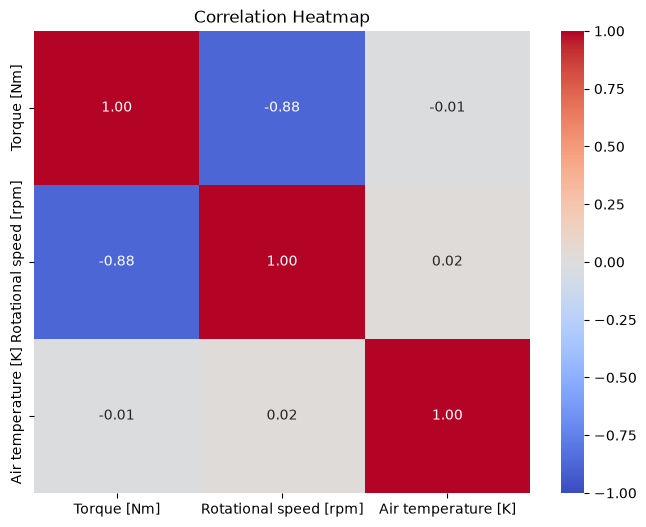

In [7]:
# Correlation heatmap
# Wählt die drei Messgrößen für die Korrelationsanalyse aus.
columns = ["Torque [Nm]", "Rotational speed [rpm]", "Air temperature [K]"]

# Berechnet die Pearson-Korrelationen zwischen allen Messgrößen.
# Das Ergebnis ist eine Matrix mit Korrelationswerten zwischen -1 und +1.
correlation = df[columns].corr()

# Erstellt eine neue Abbildung für die Korrelations-Heatmap.
plt.figure(figsize=(8, 6))

# Stellt die Korrelationsmatrix als farbige Heatmap dar.
# annot=True zeigt die Zahlenwerte in den Feldern an.
# fmt=".2f" rundet die angezeigten Werte auf zwei Nachkommastellen.
# cmap="coolwarm" legt die Farbskala fest.
# vmin und vmax begrenzen die Farbskala auf -1 und +1.
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Fügt einen Titel hinzu.
plt.title("Correlation Heatmap")

# Zeigt das fertige Diagramm an.
plt.show()

Erläuterung Pearson-Korrelationskoeffizient r:
r = -1: Perfekter negativer linearer Zusammenhang
r = 0: Kein linearer Zusammenhang
r = 1: Perfekter positiver zusammenhang

Advanced plots:

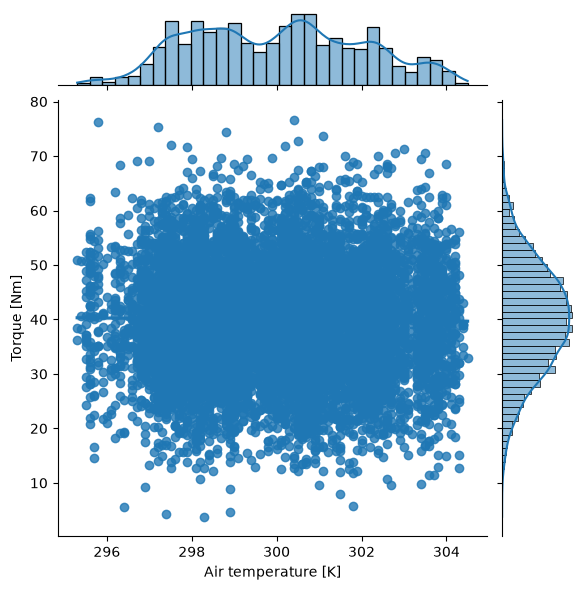

In [9]:
# Joint Plot
# Erstellt einen Jointplot für Drehmoment und Lufttemperatur
# data legt den verwendeten DataFrame fest.
# x und y bestimmen die beiden Messgrößen.
# kind="reg" erstellt ein Streudiagramm mit einer linearen Regressionsgeraden.
sns.jointplot(
    data=df,
    x="Air temperature [K]",
    y="Torque [Nm]",
    kind="reg"
)

# Zeigt das fertige Diagramm an.
plt.show()

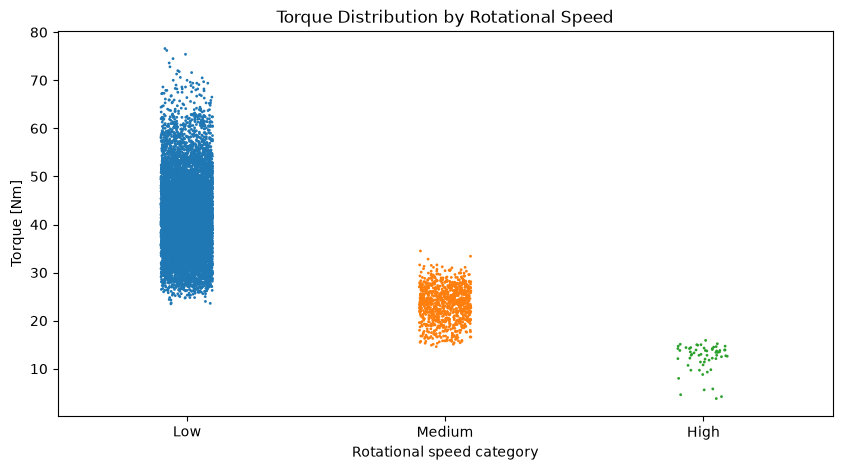

In [12]:
# Strip Plot
# Teilt die Drehzahl in drei gleich breite Bereiche ein.
# Die neuen Kategorien werden in einer zusätzlichen Spalte gespeichert.
df["Speed category"] = pd.cut(
    df["Rotational speed [rpm]"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

# Erstellt eine neue Abbildung.
plt.figure(figsize=(10, 5))

# Erstellt einen Stripplot der Drehmomentwerte.
# x zeigt die Drehzahlkategorien.
# y zeigt die zugehörigen Drehmomentwerte.
# jitter=True verschiebt die Punkte leicht horizontal,
# damit übereinanderliegende Messwerte besser erkennbar sind.
sns.stripplot(
    data=df,
    x="Speed category",
    y="Torque [Nm]",
    hue="Speed category",
    jitter=True,
    size=2
)

# Fügt einen Titel und Achsenbeschriftungen hinzu.
plt.title("Torque Distribution by Rotational Speed")
plt.xlabel("Rotational speed category")
plt.ylabel("Torque [Nm]")

# Zeigt das Diagramm an.
plt.show()

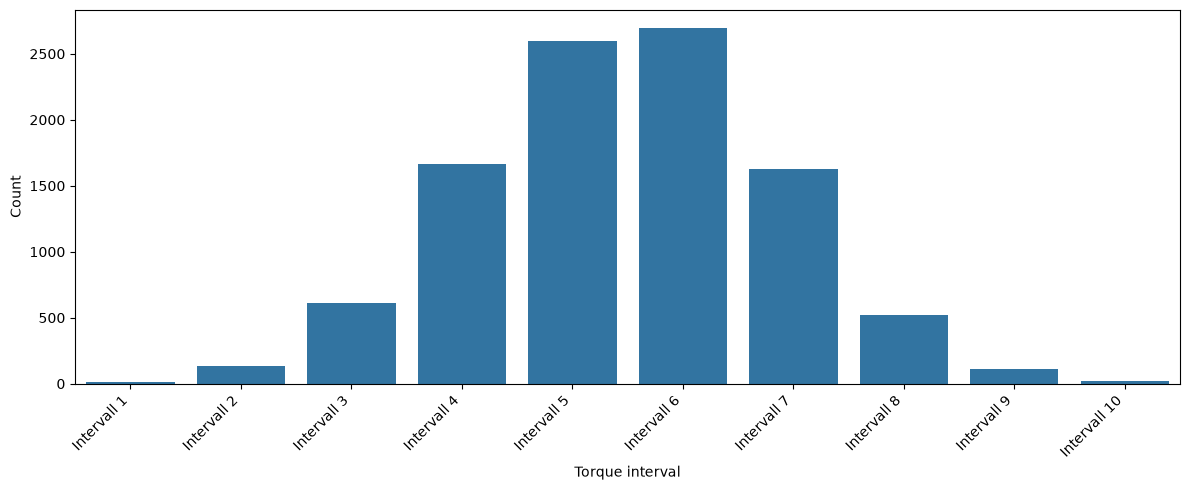

In [15]:
# Count Plot
# Unterteilt die Drehmomentwerte in zehn gleich breite Intervalle.
df["Torque bin"] = pd.cut(
    df["Torque [Nm]"], 
    bins=10, 
    labels=[f"Intervall {i}" for i in range(1, 11)])

# Zählt die Messwerte in jedem Drehmomentintervall.
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="Torque bin")

# Dreht die Intervallbeschriftungen für eine bessere Lesbarkeit.
plt.xticks(rotation=45, ha="right")
plt.xlabel("Torque interval")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Observations:
    - Are there any obvious outliners in the data?
    -> Yes, the Boxplots show that espacially torque and rotational speed have outliners.

    - Whoch tow variables seem most related?
    -> Torque and rotational speed

    - Are there any non-linear patterns visible?
    ->  A clear nonlinear relationship is visible between torque and rotational speed. 
    Torque decreases as rotational speed increases, but the relationship is not a straight line.

    - How are the distributions shaped?
    -> Torque is approximately normally distributed wirh most measurements arount 40 Nm.
       Rotational speed has a right-skewed distribution with most values around 1500 rpm.
       Air temperature does not show a clear normal distribution and has an irregular 
       distribution over the measured range.